# Iterative Image Restoration (NumPy Only)
**Objective:** Restore a motion-blurred and noisy grayscale image iteratively without explicit frequency-domain division, using two classic spatial-iterative restoration algorithms implemented purely in **NumPy**:
1. **Van Cittert / Landweber Iterative Deconvolution** (Additive gradient-descent update)
2. **Richardson-Lucy Iterative Deconvolution** (Multiplicative maximum-likelihood update for Poisson/sensor noise)

### Mathematical Formulations
Given observed degraded image $g = h * f + n$, point spread function $h$, and flipped PSF $h^T(x, y) = h(-x, -y)$:

1. **Landweber Iterative Update:**
   $$\hat{f}^{(k+1)} = \hat{f}^{(k)} + \alpha \, h^T * \left( g - h * \hat{f}^{(k)} \right)$$
   where $\alpha$ is the relaxation step size ($0 < \alpha < \frac{2}{\sigma_{\max}^2}$).

2. **Richardson-Lucy Iterative Update:**
   $$\hat{f}^{(k+1)} = \hat{f}^{(k)} \odot \left[ h^T * \left( \frac{g}{h * \hat{f}^{(k)} + \epsilon} \right) \right]$$
   where $\odot$ denotes element-wise multiplication and positivity ($\hat{f}^{(k)} \ge 0$) is naturally preserved.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a sharp 256x256 grayscale test image in [0, 1]
N = 256
x = np.linspace(-1, 1, N)
X, Y = np.meshgrid(x, x)

sharp_img = np.zeros((N, N), dtype=np.float32)
sharp_img[(X**2 + Y**2) < 0.45] = 0.85                                   # Circle
sharp_img[(np.abs(X - 0.3) < 0.18) & (np.abs(Y - 0.3) < 0.18)] = 0.4     # Square
sharp_img[35:55, 35:220] = 1.0                                           # Horizontal bar
sharp_img[35:220, 35:55] = 1.0                                           # Vertical bar

# 2. Generate 2D Motion Blur Point Spread Function (PSF)
def create_motion_psf(shape, length=17, angle=25):
    psf = np.zeros(shape, dtype=np.float32)
    center = (shape[0] // 2, shape[1] // 2)
    theta = np.deg2rad(angle)
    for i in range(-length // 2, length // 2 + 1):
        r = int(round(center[0] + i * np.sin(theta)))
        c = int(round(center[1] + i * np.cos(theta)))
        if 0 <= r < shape[0] and 0 <= c < shape[1]:
            psf[r, c] = 1.0
    return psf / np.sum(psf)

psf = create_motion_psf((N, N), length=17, angle=25)

# Fast circular 2D convolution via FFT (pure NumPy)
def conv2d_fft(img: np.ndarray, kernel_fft: np.ndarray) -> np.ndarray:
    return np.real(np.fft.ifft2(np.fft.fft2(img) * kernel_fft))

H = np.fft.fft2(np.fft.ifftshift(psf))

# 3. Degrade image: Blur + Additive Gaussian Noise
rng = np.random.default_rng(seed=42)
noise = rng.normal(0.0, 0.01, sharp_img.shape).astype(np.float32)
degraded_img = np.clip(conv2d_fft(sharp_img, H) + noise, 0.0, 1.0)

print("Degraded image ready. Shape:", degraded_img.shape)

Degraded image ready. Shape: (256, 256)


In [2]:
def landweber_restoration(
    degraded: np.ndarray,
    psf: np.ndarray,
    ground_truth: np.ndarray,
    iterations: int = 80,
    alpha: float = 1.2
):
    """Iterative Landweber Deconvolution: f_{k+1} = f_k + alpha * H^T * (g - H * f_k)"""
    H = np.fft.fft2(np.fft.ifftshift(psf))
    H_conj = np.conj(H)  # Frequency response of flipped PSF h(-x, -y)

    f_est = degraded.copy()
    psnr_history = []
    snapshots = {}

    for k in range(1, iterations + 1):
        # Forward blur of current estimate: H * f_k
        blurred_est = np.real(np.fft.ifft2(np.fft.fft2(f_est) * H))
        residual = degraded - blurred_est

        # Back-project residual: H^T * residual
        correction = np.real(np.fft.ifft2(np.fft.fft2(residual) * H_conj))

        # Iterative gradient update + non-negativity projection
        f_est = np.clip(f_est + alpha * correction, 0.0, 1.0)

        mse = np.mean((ground_truth - f_est) ** 2)
        psnr_history.append(10.0 * np.log10(1.0 / (mse + 1e-12)))

        if k in {5, 25, iterations}:
            snapshots[k] = f_est.copy()

    return f_est, psnr_history, snapshots


def richardson_lucy_restoration(
    degraded: np.ndarray,
    psf: np.ndarray,
    ground_truth: np.ndarray,
    iterations: int = 50
):
    """Iterative Richardson-Lucy Deconvolution: f_{k+1} = f_k * [H^T * (g / (H * f_k))]"""
    H = np.fft.fft2(np.fft.ifftshift(psf))
    H_conj = np.conj(H)

    # Initialize with positive constant or degraded image
    f_est = np.maximum(degraded.copy(), 1e-4)
    psnr_history = []
    snapshots = {}

    for k in range(1, iterations + 1):
        # Forward blur: H * f_k
        reblurred = np.real(np.fft.ifft2(np.fft.fft2(f_est) * H))
        reblurred = np.maximum(reblurred, 1e-6)

        # Relative blur ratio: g / (H * f_k)
        ratio = degraded / reblurred

        # Back-project ratio: H^T * ratio
        correction = np.real(np.fft.ifft2(np.fft.fft2(ratio) * H_conj))

        # Multiplicative update
        f_est = np.clip(f_est * correction, 0.0, 1.0)

        mse = np.mean((ground_truth - f_est) ** 2)
        psnr_history.append(10.0 * np.log10(1.0 / (mse + 1e-12)))

        if k in {5, 20, iterations}:
            snapshots[k] = f_est.copy()

    return f_est, psnr_history, snapshots


# Execute both iterative restoration methods
lw_final, lw_psnr, lw_snaps = landweber_restoration(degraded_img, psf, sharp_img, iterations=80, alpha=1.2)
rl_final, rl_psnr, rl_snaps = richardson_lucy_restoration(degraded_img, psf, sharp_img, iterations=50)

print(f"Landweber Final PSNR (80 iters)      : {lw_psnr[-1]:.2f} dB")
print(f"Richardson-Lucy Final PSNR (50 iters): {rl_psnr[-1]:.2f} dB")

Landweber Final PSNR (80 iters)      : 27.87 dB
Richardson-Lucy Final PSNR (50 iters): 28.18 dB


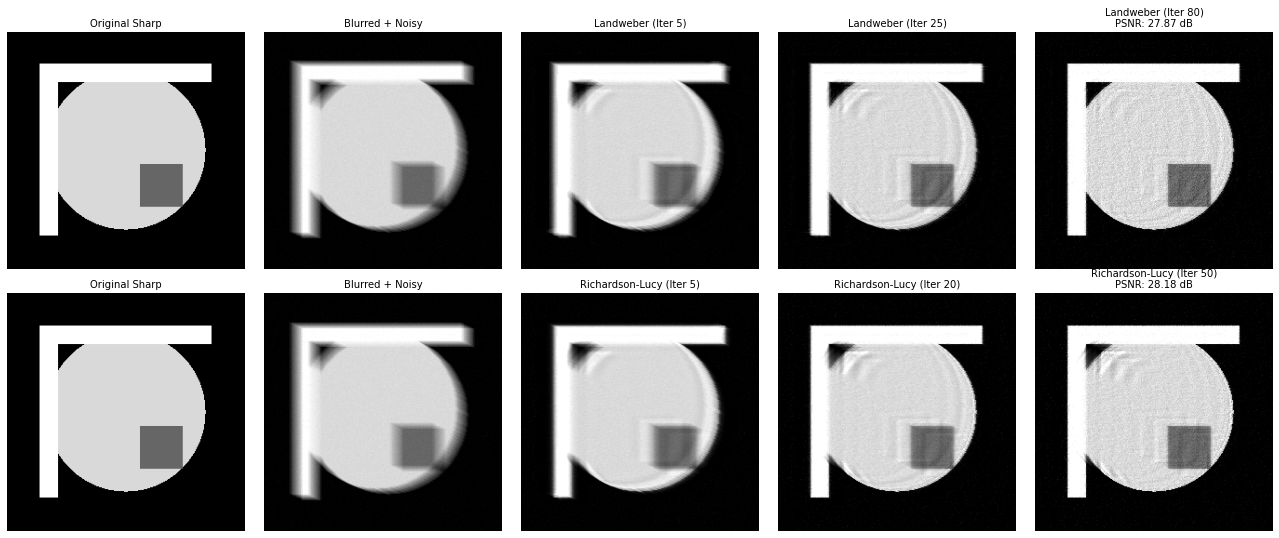

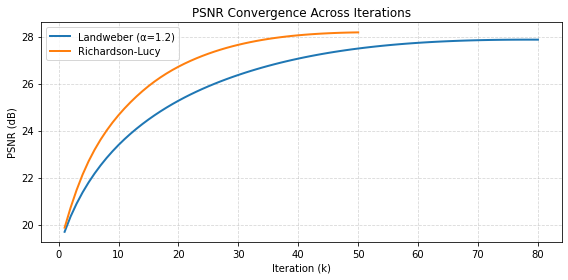

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7.5))

# Row 1: Landweber progression
lw_panels = [
    ("Original Sharp", sharp_img),
    ("Blurred + Noisy", degraded_img),
    ("Landweber (Iter 5)", lw_snaps[5]),
    ("Landweber (Iter 25)", lw_snaps[25]),
    (f"Landweber (Iter 80)\nPSNR: {lw_psnr[-1]:.2f} dB", lw_snaps[80]),
]
for ax, (title, im) in zip(axes[0], lw_panels):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

# Row 2: Richardson-Lucy progression
rl_panels = [
    ("Original Sharp", sharp_img),
    ("Blurred + Noisy", degraded_img),
    ("Richardson-Lucy (Iter 5)", rl_snaps[5]),
    ("Richardson-Lucy (Iter 20)", rl_snaps[20]),
    (f"Richardson-Lucy (Iter 50)\nPSNR: {rl_psnr[-1]:.2f} dB", rl_snaps[50]),
]
for ax, (title, im) in zip(axes[1], rl_panels):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Plot PSNR vs. Iteration Curve (shows semi-convergence behavior)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(lw_psnr) + 1), lw_psnr, label="Landweber (α=1.2)", linewidth=2)
ax.plot(range(1, len(rl_psnr) + 1), rl_psnr, label="Richardson-Lucy", linewidth=2)
ax.set_title("PSNR Convergence Across Iterations")
ax.set_xlabel("Iteration (k)")
ax.set_ylabel("PSNR (dB)")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()